In [ ]:
# Lấy dữ liệu từ file đã lưu
import pandas as pd

train_df = pd.read_csv("../data/processed_train.csv")

train_df.head()

,review_text,label,text_length
0,but i haven't received it yet since ordering i...,negative,140
1,"well written articles, good start up info as w...",positive,88
2,"love this magazine, i always find a few things...",positive,161
3,i have read this magazine since i was a teen.....,positive,101
4,don't feel like supporting a racist woman who ...,negative,88


In [2]:
# X: Nội dung đánh giá sản phẩm
X = train_df["review_text"]

# y: Nhãn cảm xúc
y = train_df["label"]

print("Số lượng mẫu:", len(X))
print("Các nhãn:", y.unique())

Số lượng mẫu: 1000
Các nhãn: <StringArray>
['negative', 'positive']
Length: 2, dtype: str


In [3]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Số lượng mẫu Training:", len(X_train))
print("Số lượng mẫu Validation:", len(X_val))

Số lượng mẫu Training: 800
Số lượng mẫu Validation: 200


In [4]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

In [5]:
# Khởi tạo mô hình Baseline
baseline_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=10000
    )),

    ("classifier", MultinomialNB())
])

In [6]:
# Huấn luyện mô hình
baseline_model.fit(X_train, y_train)

print("Huấn luyện mô hình Baseline thành công!")

Huấn luyện mô hình Baseline thành công!


In [7]:
# Dự đoán nhãn cảm xúc
y_pred = baseline_model.predict(X_val)

# Hiển thị một số kết quả dự đoán
result = pd.DataFrame({
    "Review": X_val,
    "Actual": y_val,
    "Predicted": y_pred
})

print(result.head(10))

                                                Review    Actual Predicted
274  the articles are so in depth and hard to put d...  positive  positive
17                         great deal for a low price!  positive  positive
394  love this magazine and now i can view it on my...  positive  positive
290  excellent information in this little magazine!...  positive  positive
974  very poorly written with little content. not w...  negative  negative
338  for some reason it takes forever to get the fi...  negative  negative
716  i love this magazine so much. it is so informa...  positive  positive
935                                         awesome! !  positive  positive
706  i just received the first issue of a full year...  negative  negative
995  i have no comment on the quality of the magazi...  negative  negative


In [8]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [9]:
accuracy = accuracy_score(y_val, y_pred)

print("Accuracy:", accuracy)
print("Accuracy (%):", accuracy * 100)

Accuracy: 0.96
Accuracy (%): 96.0


In [10]:
print(classification_report(y_val, y_pred))

              precision    recall  f1-score   support

    negative       1.00      0.91      0.95        89
    positive       0.93      1.00      0.97       111

    accuracy                           0.96       200
   macro avg       0.97      0.96      0.96       200
weighted avg       0.96      0.96      0.96       200



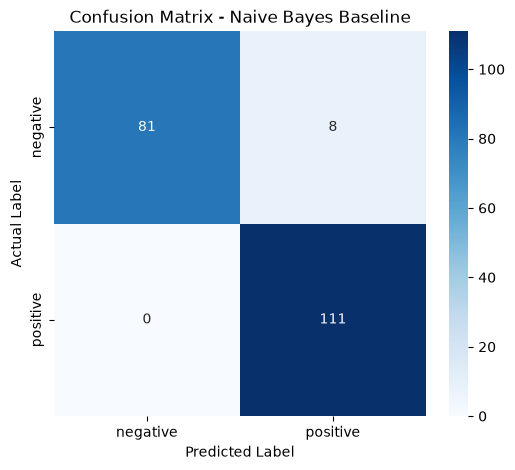

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_val,
    y_pred,
    labels=baseline_model.classes_
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=baseline_model.classes_,
    yticklabels=baseline_model.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Naive Bayes Baseline")

plt.show()

In [12]:
from sklearn.metrics import precision_score, recall_score, f1_score

baseline_results = pd.DataFrame({
    "Model": ["Multinomial Naive Bayes"],
    "Accuracy": [accuracy_score(y_val, y_pred)],
    "Precision": [
        precision_score(y_val, y_pred, average="weighted")
    ],
    "Recall": [
        recall_score(y_val, y_pred, average="weighted")
    ],
    "F1-score": [
        f1_score(y_val, y_pred, average="weighted")
    ]
})

print(baseline_results.round(4))

                     Model  Accuracy  Precision  Recall  F1-score
0  Multinomial Naive Bayes      0.96     0.9627    0.96    0.9598
